# Iterative Methods for Solving Linear Systems

Iterative techniques are rarely used for solving linear systems of small dimension because the computation time required for convergence usually exceeds that required for direct methods such as Gaussian elimination.  However, for very large systems, especially sparse systems (systems with a high percentage of 0 entries in the matrix), these iterative techniques can be very efficient in terms of computational run times and memory usage.

An iterative technique starts to solve the matrix equation $\mathbf{A}\vec{x} = \vec{b}$ starts with an initial approximation $\vec{x^0}$ and generates a sequence of vectors $\{\vec{x}^1,\vec{x}^2,\ldots, \vec{x}^N\}$ that converges to $\vec{x}$ as $N\rightarrow\infty$. These techniques involve a process that converts the system $\mathbf{A}\vec{x}=\vec{b}$ to an equivalent system of the form $\vec{x}=\mathbf{T}\vec{x}+\vec{c}$. The process then follows, for an initial guess $\vec{x}^0$

Starting with an initial guess $\vec{x}_0$, we convert

$$
\mathbf{A}\vec{x} = \vec{b} \qquad \to \qquad \vec{x} = \mathbf{T}\vec{x} + \vec{c}
$$

\begin{align}
\vec{x}^1 &= \mathbf{T}\vec{x}^0 + \vec{c}\\
\vec{x}^2 &= \mathbf{T}\vec{x}^1 + \vec{c}\\
&\phantom{=}\vdots\\
\vec{x}^N &= \mathbf{T}\vec{x}^{N-1} + \vec{c}\\
\end{align}

In principle the sequence above only depends on the matrix-vector multiplication and vector-vector addition operations.

We will stop the iteration when some convergence criterion has been reached. A popular convergence criterion uses the $L_{\infty}$norm. Recall:

In [16]:
import numpy as np

# For a vector
vector = np.array([-6, 4, 2])
l_infinity_norm_vector = np.linalg.norm(vector, ord=1)
print(f"L-infinity norm of the vector: {l_infinity_norm_vector}")

L-infinity norm of the vector: 12.0


## An example using an iterative method

Consider the system:

$$
\begin{matrix} E_1: & 10x_1 & -x_2 & +2x_3 & & =& 6\\E_2: & -x_1 & +11x_2 & -x_3 & +3x_4 & =&25\\E_3: & 2x_1 & -x_2 & + 10x_3 & -x_4 & =&-11\\E_4: &  & -3x_2 & -x_3 & +8x_4 & = &15\end{matrix}
$$

Let us solve each equation, $E_j$, for the variable $x_j$.

$$
\begin{matrix} E_1: & x_1 =&  &\frac{1}{10}x_2& - \frac{1}{5}x_3 &  & +\frac{3}{5}\\
E_2: & x_2 = &\frac{1}{11}x_1 & &\frac{1}{11}x_3 & -\frac{3}{11}x_4 & +\frac{25}{11}\\
E_3: & x_3 = &-\frac{1}{5}x_1 & +\frac{1}{10}x_2 & & +\frac{1}{10}x_4 & -\frac{11}{10}\\
E_4: & x_4 = & & -\frac{3}{8}x_2 & + \frac{1}{8}x_3 & & +\frac{15}{8} \end{matrix}
$$

using the notation introduced previously we have

$$
\vec{x}^1 = \begin{bmatrix} 0 & \frac{1}{10} & -\frac{1}{5} & 0\\
\frac{1}{11} & 0 & \frac{1}{11} & -\frac{3}{11}\\
-\frac{1}{5} & \frac{1}{10} & 0 & \frac{1}{10}\\
0 & -\frac{3}{8} & \frac{1}{8} & 0 \end{bmatrix}\vec{x}_0 + \begin{bmatrix}\frac{3}{5}\\\frac{25}{11}\\-\frac{11}{10}\\\frac{15}{8}\end{bmatrix},$$

for

$$\vec{x}^0 = \begin{bmatrix}0\\0\\0\\0\end{bmatrix}, \qquad \vec{x}^1 = \begin{bmatrix}0.6000\\2.2727\\-1.1000\\1.8750\end{bmatrix}$$

we repeat this process until the desired convergence has been reached. This technique is called the Jacobi iterative method.

### Psuedocode for Jacobi iteration

For the matrix equation $\mathbf{A} \vec{x} = \vec{b}$ with an initial guess $\vec{x}^0$.

\begin{equation}
A = \begin{bmatrix}a_{11}&a_{12}&...&a_{1n}\\a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\a_{n1}&...&...&a_{nn}\end{bmatrix}, \quad \vec{b} = \begin{bmatrix} b_{1} \\ b_{2} \\ \vdots \\ b_{n}\end{bmatrix}, \quad \vec{x}^{0} = \begin{bmatrix} x^0_{1} \\ x^0_{2} \\ \vdots \\ x^0_{n}\end{bmatrix},
\end{equation}


While $\frac{\Vert \vec{x}_k - \vec{x}_{k-1} \Vert_{L_\infty}}{\Vert \vec{x} \Vert_{L_\infty}}>$ tolerance

$\phantom{--}$ For $i = 1, 2, \ldots, n$

$\phantom{----} x^k_i = \frac{1}{a_{ii}} \left.\left( -\sum_{\substack{j=1 \\ i \ne j}}^n a_{ij} x^k_j  + b_i\right)  \right.$

### Jacobi iteration

In [17]:
import numpy as np

In [18]:
import numpy as np

def jacobi(A, b, x0, tol=1e-6, max_iterations=1000):
    """
    Solves a system of linear equations Ax = b using the Jacobi method.

    Args:
        A (numpy.ndarray): The coefficient matrix.
        b (numpy.ndarray): The constant vector.
        x0 (numpy.ndarray): The initial guess for the solution vector.
        tol (float): The tolerance for convergence.
        max_iterations (int): The maximum number of iterations.

    Returns:
        numpy.ndarray: The approximate solution vector.
    """
    n = len(b)
    x = x0.copy()  # Current approximation
    x_new = np.zeros_like(x) # New approximation for the next iteration

    for k in range(max_iterations):
        for i in range(n):
            sum_val = 0
            for j in range(n):
                if i != j:
                    sum_val += A[i, j] * x[j]
            x_new[i] = (b[i] - sum_val) / A[i, i]

        if (np.linalg.norm(x_new, ord=np.inf) == 0): break
            #raise AssertionError("error")
        # Check for convergence
        if np.linalg.norm(x_new - x, ord=np.inf)/np.linalg.norm(x_new, ord=np.inf) < tol:
            print(f"Converged after {k+1} iterations.")
            return x_new

        x = x_new.copy() # Update for the next iteration

    print(f"Jacobi method did not converge within {max_iterations} iterations.")
    return x

# Example Usage:
# Define the system
A = np.array([[4, -1, 0],
              [-1, 4, -1],
              [0, -1, 4]], dtype=float)

b = np.array([10, 20, 10], dtype=float)

# Initial guess (often a vector of zeros)
x0 = np.zeros_like(b, dtype=float)

# Solve using Jacobi method
solution = jacobi(A, b, x0, tol=1e-12)

print("\nApproximate solution:")
print(solution)

# Verify with numpy's linalg.solve
exact_solution = np.linalg.solve(A, b)
print("\nExact solution (using numpy.linalg.solve):")
print(exact_solution)

Converged after 28 iterations.

Approximate solution:
[4.28571429 7.14285714 4.28571429]

Exact solution (using numpy.linalg.solve):
[4.28571429 7.14285714 4.28571429]


### Observations on the Jacobi iterative method

Let's consider a matrix $\mathbf{A}$, in which we split into three matrices, $\mathbf{D}$, $\mathbf{U}$, $\mathbf{L}$, where these matrices are diagonal, upper triangular, and lower triangular respectively.

$$
A = \begin{bmatrix}a_{11}&a_{12}&\ldots&a_{1n}\\a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\a_{n1}&\ldots&\ldots&a_{nn}\end{bmatrix}, D = \begin{bmatrix}a_{11}&0&\ldots&0\\0&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\0&\ldots&\ldots&a_{nn}\end{bmatrix}, \\
L = \begin{bmatrix}0&0&\ldots&0\\-a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\-a_{n1}&\ldots&-a_{n(n-1)}&0\end{bmatrix}, U = \begin{bmatrix}0&-a_{12}&\ldots&-a_{1n}\\\vdots&\ddots& &\vdots\\\vdots& &\ddots&-a_{(n-1)n}\\0&\ldots&\ldots&0\end{bmatrix}
$$

If we let $\mathbf{A = D-L-U}$, then the matrix equation $\mathbf{A}\vec{x} = \vec{b}$ becomes

\begin{equation}
\left(\mathbf{D-L-U}\right)\vec{x} = \vec{b} \quad \mathrm{or} \quad \mathbf{D}\vec{x} = \left(\mathbf{L+U}\right)\vec{x}+\vec{b}
\end{equation}

if $\mathbf{D}^{-1}$ exists, that implies $a_{jj} \neq 0$, then

$$\vec{x} = \mathbf{D}^{-1}\left(\mathbf{L+U}\right)\vec{x}+\mathbf{D}^{-1}\vec{b}$$

The results in the matrix form of the Jacobi iteration method

\begin{equation}
\vec{x}^k = \mathbf{D}^{-1}\left(\mathbf{L+U}\right)\vec{x}^{k-1}+\mathbf{D}^{-1}\vec{b}
\end{equation}

We can see that one requirement for the Jacobi iteration to work is for $a_{ii} \neq 0$. This may involve row exchanges before iterating for some linear systems. Strict diagonal dominance gives conditions for the convergence of the Jacobi method:


An $n\times n$ matrix $A$ is said to be **strictly diagonally dominant** if for each $i$, $1\le i\le n$, $$\sum_{1 \leq j \leq n, j \neq i}|a_{i,j}|  < |a_{i,i}|,$$
i.e., the absolute value of each diagonal elment of $A$ is strictly greater than the absolute sum of the rest of the elemtents in the same row.

## Gauss-Seidel iteration: An improvement to the Jacobi iterative method

During the Jacobi iteration we always use the components of $\vec{x}^{k-1}$ to compute $\vec{x}^{k}$ but for $i > 1, {x}^{k}_1, \ldots, {x}^{k}_{i-1}$ are already computed and are most likely the best approximations of the real solution.  Therefore, we can calculate ${x}^{k}_i$ using the most recently calculated values when available. This technique is called *Gauss-Seidel iteration*. The pseudocode is as follows

### Pseudocode for Gauss-Seidel iteration

For the matrix equation $\mathbf{A} \vec{x} = \vec{b}$ with an initial guess $\vec{x}^0$.

$$
A=\begin{bmatrix}a_{11}&a_{12}&\ldots&a_{1n}\\a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\a_{n1}&\ldots&\ldots&a_{nn}\end{bmatrix}, \bar{b} = \begin{bmatrix}b_1\\b_1\\\vdots\\b_n\end{bmatrix}, \bar{x}_0 = \begin{bmatrix}x^{0}_1\\x^{0}_2\\\vdots\\x^{0}_n\end{bmatrix}
$$



While $\frac{\Vert\vec{x}^{k}-\vec{x}^{k-1}\Vert_{L_\infty}}{\Vert\bar{x}^{k}\Vert_{L_\infty}} >$ tolerance

$\phantom{--}$ For $i = 1, 2, ..., n$

$\phantom{----} x^{k}_i = \left.\left(-\sum_{j=1}^{i-1}a_{ij}x^{k}_j-\sum_{j=i+1}^{n}a_{ij}x^{k-1}_j+b_i\right) \middle/ {a_{ii}}\right.$

### Gauss-Seidel iteration

In [19]:
def gauss_seidel(A, b, x0, tol=1e-6, max_iter=100):
    """
    Solves a system of linear equations Ax = b using the Gauss-Seidel method.

    Args:
        A (numpy.ndarray): The coefficient matrix.
        b (numpy.ndarray): The constant vector.
        x0 (numpy.ndarray): The initial guess for the solution vector.
        tol (float): The tolerance for convergence.
        max_iter (int): The maximum number of iterations.

    Returns:
        numpy.ndarray: The approximate solution vector.
        int: The number of iterations taken.
    """
    n = len(b)
    x = x0.copy()  # Make a copy to avoid modifying the original x0

    for iteration in range(max_iter):
        x_prev = x.copy()  # Store the previous iteration's values

        for i in range(n):
            sum_val = 0
            for j in range(n):
                if i != j:
                    sum_val += A[i, j] * x[j]
            x[i] = (b[i] - sum_val) / A[i, i]

        # Check for convergence
        if np.linalg.norm(x - x_prev)/np.linalg.norm(x) < tol:
            print(f"Converged in {iteration + 1} iterations.")
            return x, iteration + 1

    print(f"Did not converge within {max_iter} iterations.")
    return x, max_iter

# Example usage:
# Define the system Ax = b
A = np.array([[4, 1, 2],
              [3, 5, 1],
              [1, 1, 3]])

b = np.array([4, 7, 3])

# Initial guess
x0 = np.array([0.0, 0.0, 0.0])

# Solve using Gauss-Seidel
solution, iterations = gauss_seidel(A, b, x0, tol=1e-12)

print("Approximate solution:", solution)
print("Iterations:", iterations)

Converged in 19 iterations.
Approximate solution: [0.5 1.  0.5]
Iterations: 19


### Observations on the Gauss-Seidel iterative method

Let's consider a matrix $\mathbf{A}$, in which we split into three matrices, $\mathbf{D, U, L}$, where these matrices are diagonal, upper triangular, and lower triangular respectively.

$$
A = \begin{bmatrix}a_{11}&a_{12}&\ldots&a_{1n}\\a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\a_{n1}&\ldots&\ldots&a_{nn}\end{bmatrix}, D = \begin{bmatrix}a_{11}&0&\ldots&0\\0&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\0&\ldots&\ldots&a_{nn}\end{bmatrix}, \\ L = \begin{bmatrix}0&0&\ldots&0\\-a_{21}&\ddots& &\vdots\\\vdots& &\ddots&\vdots\\-a_{n1}&\ldots&-a_{n(n-1)}&0\end{bmatrix}, U = \begin{bmatrix}0&-a_{12}&\ldots&-a_{1n}\\\vdots&\ddots& &\vdots\\\vdots& &\ddots&-a_{(n-1)n}\\0&\ldots&\ldots&0\end{bmatrix}
$$

We will leave, as an exercise for the student, the derivation, but the matrix equation for the Gauss-Seidel iteration method is as follows:

$$\vec{x}^k = \left(\mathbf{D-L}\right)^{-1}\mathbf{U}\vec{x}^{k-1}+\left(\mathbf{D-L}\right)^{-1}\vec{b}$$

In order for the lower triangular matrix $\mathbf{D-L}$ to be invertible it is necessary and sufficient for $a_{ii}\neq 0$. As before, this may involve row exchanges before iterating for some linear systems.

### **Homework**:

In this assignment, we show the convergence of Jacobi and Gauss-Seidel iterations for solving a linear system. We will consider the $L_2$ norm of error versus the iteration steps and show how the $L_2$ norm decreases, if at all, as the number of iterations increase. We use both methods to obtain the solution of

$$ {\bf Ax}={\bf y}$$

**Assignment**:
1. Use `jacopbi` and `gauss_seidel` functions to solve the system of
equations in HW2 with $n=80$.
2. Confirm that your solution is correct, up to the specified tolerance,
by comparing the results with the results of solving the linear system using the
Gaussian elimination. Explain why you do not need to worry about pivoting.
3. One a same plot, plot $|x^{k+1}-x^{k}|_2$ for both methods, where
$k$ is the iteration step and $|.|_2$ is the $L_2$ norm. Describe
your observation as how the norm decreases in each method.
4. Plot the computational time of each method for $n=10,100,1000,1000$,
while keeping ``tol`` fixed, and describe the computational complexity of
the methods, by plotting the computational time as a function of $n$.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.linalg import solve_banded

def build_system(n, a=0.0, b_end=np.pi/2):
    h = (b_end - a) / n
    x = np.linspace(a, b_end, n + 1)
    N = n + 1
    A = np.zeros((N, N))
    b = np.zeros(N)

    A[0, 0] = 1.0
    for i in range(1, N - 1):
        A[i, i - 1] = 1.0
        A[i, i]     = -2.0 - 4.0 * h**2
        A[i, i + 1] = 1.0
        b[i] = 4.0 * h**2 * x[i]
    A[-1, -2] = 2.0
    A[-1, -1] = -2.0 - 4.0 * h**2
    b[-1] = 4.0 * h**2 * x[-1]
    return x, A, b

# Gaussian elimination from HW2
def forward_sub(L, b):
    n = L.shape[0]
    x = np.zeros(n)
    for i in range(n):
        tmp = b[i]
        for j in range(i):
            tmp -= L[i, j] * x[j]
        x[i] = tmp / L[i, i]
    return x

def back_sub(U, b):
    n = U.shape[0]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        tmp = b[i]
        for j in range(i + 1, n):
            tmp -= U[i, j] * x[j]
        x[i] = tmp / U[i, i]
    return x

def lu_decomp(A):
    N = A.shape[0]
    L = np.eye(N)
    U = A.copy()
    for c in range(N):
        for r in range(c + 1, N):
            factor = U[r, c] / U[c, c]
            L[r, c] = factor
            U[r, :] -= factor * U[c, :]
    return L, U

def gauss_elim(A, b):
    L, U = lu_decomp(A)
    return back_sub(U, forward_sub(L, b))

### Jacobi and Gauss-Seidel

Same methods and stopping test as the class versions, but they also save $\|x^{k+1}-x^k\|_2$ each step for part 3. Since $A$ is tridiagonal, they only use the 3 diagonals. The class versions loop over the whole matrix, which is way too slow for $n=1000$.

In [21]:
def jacobi(A, b, x0, tol=1e-6, max_iterations=10**6):
    d, lo, up = np.diag(A), np.diag(A, -1), np.diag(A, 1)
    x = x0.copy()
    hist = []
    for k in range(max_iterations):
        rhs = b.copy()
        rhs[1:]  -= lo * x[:-1]
        rhs[:-1] -= up * x[1:]
        x_new = rhs / d
        hist.append(np.linalg.norm(x_new - x, 2))
        if np.linalg.norm(x_new - x, np.inf) / np.linalg.norm(x_new, np.inf) < tol:
            return x_new, np.array(hist)
        x = x_new
    print("Jacobi did not converge")
    return x, np.array(hist)

def gauss_seidel(A, b, x0, tol=1e-6, max_iter=10**6):
    d, lo, up = np.diag(A), np.diag(A, -1), np.diag(A, 1)
    ab = np.zeros((2, len(b)))     # (D - L) in banded form
    ab[0] = d
    ab[1, :-1] = lo
    x = x0.copy()
    hist = []
    for k in range(max_iter):
        rhs = b.copy()
        rhs[:-1] -= up * x[1:]
        x_new = solve_banded((1, 0), ab, rhs)
        hist.append(np.linalg.norm(x_new - x, 2))
        if np.linalg.norm(x_new - x, np.inf) / np.linalg.norm(x_new, np.inf) < tol:
            return x_new, np.array(hist)
        x = x_new
    print("Gauss-Seidel did not converge")
    return x, np.array(hist)

### 1. Solve with $n = 80$

In [22]:
n = 80
tol = 1e-10
xg, A, b = build_system(n)
x0 = np.zeros_like(b)

y_jac, hist_jac = jacobi(A, b, x0, tol=tol)
y_gs,  hist_gs  = gauss_seidel(A, b, x0, tol=tol)
print("Jacobi iterations:      ", len(hist_jac))
print("Gauss-Seidel iterations:", len(hist_gs))

Jacobi iterations:       16637
Gauss-Seidel iterations: 8668


### 2. Compare with Gaussian elimination

In [23]:
y_ge = gauss_elim(A, b)
print("Jacobi       max diff:", np.max(np.abs(y_jac - y_ge)))
print("Gauss-Seidel max diff:", np.max(np.abs(y_gs - y_ge)))

Jacobi       max diff: 1.1119069487364186e-07
Gauss-Seidel max diff: 5.5613566862788844e-08


* Both about 10^{-7}, so the solutions are good.
* That's bigger than tol because the stopping test checks how much $x$ changes per step, not the real error. When convergence is slow the real error ends up a lot bigger than the last step.
* A is strictly diagonally dominant (2+4h^2 > 1+1 in every row). That stays true during elimination, so the pivots never get zero or small.

###
3. $|x^{k+1} -x^{k}|_2$   vs iteration

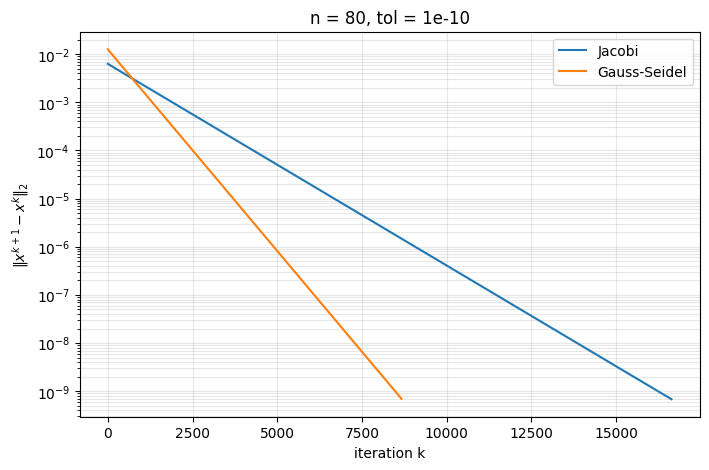

In [24]:
plt.figure(figsize=(8, 5))
plt.semilogy(hist_jac, label='Jacobi')
plt.semilogy(hist_gs,  label='Gauss-Seidel')
plt.xlabel('iteration k'); plt.ylabel(r'$\|x^{k+1}-x^k\|_2$')
plt.title(f'n = {n}, tol = {tol:g}')
plt.grid(which='both', alpha=0.3); plt.legend(); plt.show()

* Both are straight lines on the log plot, so the norm drops by the same factor every iteration (linear convergence).
* It's slow because the matrix is only barely diagonally dominant (2+4h^2 vs $2$).
* Gauss-Seidel's line is about twice as steep, so it takes about half the iterations of Jacobi since it uses the new values right away.

### 4. Computational time vs $n$
`tol fixed at $10^{-6}$. n = 10, 100, 1000.

In [ ]:
tol_t = 1e-6
ns = [10, 100, 1000, 10000]
t_jac, t_gs = [], []

for n in ns:
    _, A, b = build_system(n)
    x0 = np.zeros_like(b)

    t0 = time.perf_counter(); _, h1 = jacobi(A, b, x0, tol=tol_t); t_jac.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); _, h2 = gauss_seidel(A, b, x0, tol=tol_t); t_gs.append(time.perf_counter() - t0)
    print(f"n={n:5d}  Jacobi: {len(h1):7d} its {t_jac[-1]:7.3f} s   GS: {len(h2):7d} its {t_gs[-1]:7.3f} s")

plt.figure(figsize=(7, 5))
plt.loglog(ns, t_jac, 'o-', label='Jacobi')
plt.loglog(ns, t_gs, 's-', label='Gauss-Seidel')
plt.xlabel('n'); plt.ylabel('time (s)'); plt.title(f'Run time, tol = {tol_t:g}')
plt.grid(which='both', alpha=0.3); plt.legend(); plt.show()

n=   10  Jacobi:     182 its   0.008 s   GS:      97 its   0.015 s
n=  100  Jacobi:   10336 its   0.252 s   GS:    5717 its   0.616 s


* Time grows a lot faster than n. Each iteration is O(n), but the number of iterations also grows, roughly like n^2 in theory, since the convergence factor gets closer to 1 as h shrinks. So the total is around O(n^3).
* In my run it grew a bit slower than that, partly because with a fixed tol the stopping test is hit earlier for big n, and partly because at these sizes NumPy overhead dominates each iteration.
* Gauss-Seidel takes about half the iterations but is slower in actual time, since each step is a sweep instead of one vector operation.
* For this problem a direct solve is way faster. Jacobi/GS are more useful for huge sparse systems.